# Results analysis

What the dispatch of 2018–2020 actually did, read off the plan the model
wrote: `data/results/dispatch_plan.csv`, plus the committed measurement CSVs
under `docs/model/`.

Two things happen here. §1 re-derives every figure
[`docs/model/results.md`](../docs/model/results.md) quotes and diffs it
against the documented value, so the document and the plan cannot drift apart
unnoticed. §2 onwards goes past the document, into the dispatch behaviour the
plan records but the prose only asserts.

Nothing in this notebook solves anything — every number is an arithmetic
reading of a committed artefact, so a full run is seconds. If the plan is
missing, solve one first:

```
uv run battery-case dispatch
```

Percent-format script: each `# %%` starts a cell. In Zed, put the cursor in a
cell and press `ctrl-shift-enter` to run it in the REPL.

In [1]:
import hashlib
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython import get_ipython
from matplotlib.ticker import FuncFormatter

from battery_case import load_battery_spec
from battery_case.data_io.paths import RESULTS_DIR
from battery_case.modelling.parameters import ModelParameters, prorated_cycle_budget
from battery_case.modelling.plan import summarise

# Reload the package on edit, when running under an IPython kernel. Spelled out
# rather than as %load_ext so this file stays importable, lintable Python.
_ipython = get_ipython()
if _ipython is not None:
    _ipython.run_line_magic("load_ext", "autoreload")
    _ipython.run_line_magic("autoreload", "2")

# The palette fixed in scripts/plot_cutting_plane.py, so the figures here and
# the figures in the documents are one set. CHARGE and DISCHARGE keep one
# colour each throughout the notebook; identity is never left to colour alone.
CHARGE = "#2a78d6"
DISCHARGE = "#eb6834"
INK = "#0b0b0b"
MUTED = "#52514e"
SURFACE = "#fcfcfb"

sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "figure.dpi": 110,
        "axes.labelcolor": INK,
        "text.color": INK,
    }
)

GBP = FuncFormatter(lambda v, _: f"£{v:,.0f}")

## §0 Provenance

Which plan is being read, and whether it is the shape the rest of the
notebook assumes. A stale or partial plan should be visible here rather than
halfway down a figure.

In [2]:
PLAN_PATH = RESULTS_DIR / "dispatch_plan.csv"

if not PLAN_PATH.exists():
    raise SystemExit(f"no plan at {PLAN_PATH}\nsolve one first:  uv run battery-case dispatch")

spec = load_battery_spec()
params = ModelParameters.from_spec(spec)
plan = pd.read_csv(PLAN_PATH, index_col=0, parse_dates=True)

digest = hashlib.sha256(PLAN_PATH.read_bytes()).hexdigest()
written = datetime.fromtimestamp(PLAN_PATH.stat().st_mtime, tz=UTC)

print(f"plan     {PLAN_PATH}")
print(f"written  {written:%Y-%m-%d %H:%M} UTC")
print(f"sha256   {digest[:16]}…")
print(f"horizon  {plan.index[0]:%Y-%m-%d %H:%M} to {plan.index[-1]:%Y-%m-%d %H:%M}")
print(f"periods  {len(plan):,}")
print(f"round trip  {params.round_trip_efficiency:.2%}   cycle budget  {params.cycle_budget:,.0f}")

plan     /home/gui/Projects/BatteryCase/data/results/dispatch_plan.csv
written  2026-10-18 22:06 UTC
sha256   26ad94450bb8663b…
horizon  2018-01-01 00:00 to 2020-12-31 23:30
periods  52,608
round trip  90.25%   cycle budget  5,000


In [3]:
# The assumptions every cell below rests on, checked once.
gaps = plan.index.to_series().diff().dropna().unique()

assert len(plan) == 52_608, f"expected the full three years, got {len(plan):,} periods"
assert list(gaps) == [pd.Timedelta("30min")], f"not a regular half-hourly index: {gaps}"
assert not plan.index.has_duplicates, "duplicate timestamps"
assert not plan.isna().to_numpy().any(), "missing values in the plan"
assert plan["storage_mwh"].between(0.0, params.nominal_volume_mwh + 1e-6).all(), (
    "storage outside [0, nominal volume]"
)
# The cycle count is cumulative, so it must not fall — but it is accumulated
# window by window in floating point, and 369 of its 52,607 steps come back
# negative by up to 6e-11. That is solver and summation noise, eleven orders of
# magnitude below one cycle, not a decision to un-spend wear.
worst_step = float(plan["cycles"].diff().min())
assert worst_step > -1e-9, f"the cycle count falls by {worst_step:,.3g}, beyond rounding noise"

print("provenance checks passed")
print(f"worst backward step in the cycle count:  {worst_step:,.3g}  (rounding noise)")

provenance checks passed
worst backward step in the cycle count:  -6.14e-11  (rounding noise)


In [4]:
# The derived columns the rest of the notebook works in. Signed net power is
# the one that makes a dispatch figure readable: positive is delivering.
delivered = 1.0 - params.discharge_loss

plan["charge_mw"] = plan["charge_1_mw"] + plan["charge_2_mw"]
plan["discharge_mw"] = plan["discharge_1_mw"] + plan["discharge_2_mw"]
plan["net_mw"] = plan["discharge_mw"] - plan["charge_mw"]
plan["spread"] = plan["price_2"] - plan["price_1"]

# A trader with both markets open buys at the cheaper of the two and sells into
# the dearer, in every period. These two columns are that view of the day, and
# everything below that talks about "the day's prices" is built from them.
plan["buy_at"] = plan[["price_1", "price_2"]].min(axis=1)
plan["sell_at"] = plan[["price_1", "price_2"]].max(axis=1)

day = plan.index.normalize()

# How many periods a day the plan is actually on each side. These two counts
# calibrate the harvestable spread below: the battery does not take the day's
# one best trade, it takes about fourteen of them.
PERIODS_SELLING = round(float((plan["discharge_mw"] > 1e-5).groupby(day).sum().mean()))
PERIODS_BUYING = round(float((plan["charge_mw"] > 1e-5).groupby(day).sum().mean()))


def harvestable_spread(frame: pd.DataFrame) -> float:
    """Mean of the day's best selling periods less its cheapest buying ones.

    The day's range — its highest price less its lowest — is the spread on one
    perfect trade, and the battery makes about three cycles a day, so the range
    overstates what is reachable. Averaging the top ``PERIODS_SELLING`` prices
    against the bottom ``PERIODS_BUYING`` measures the same thing over the
    volume the battery can actually move.

    It stays exogenous: the two counts are calibrated once, on the plan's
    average behaviour over three years, but each day's value is read off that
    day's prices alone and knows nothing of what the plan did that day.
    """
    top = np.sort(frame["sell_at"].to_numpy())[::-1][:PERIODS_SELLING].mean()
    bottom = np.sort(frame["buy_at"].to_numpy())[:PERIODS_BUYING].mean()
    return float(top - bottom)


daily = pd.DataFrame(
    {
        "profit_gbp": plan["net_revenue_gbp"].resample("D").sum(),
        "cycles": plan["cycles"]
        .resample("D")
        .last()
        .diff()
        .fillna(plan["cycles"].resample("D").last().iloc[0]),
        "mean_price": plan[["price_1", "price_2"]].mean(axis=1).resample("D").mean(),
        # The day's range: the one best trade available. §2 uses it, where the
        # question is whether *any* trade clears the round trip.
        "day_range": plan["sell_at"].groupby(day).max() - plan["buy_at"].groupby(day).min(),
        # What the battery's own throughput can reach. §4 and §6 use this.
        "harvestable_spread": plan.groupby(day).apply(harvestable_spread, include_groups=False),
        "delivered_mwh": params.dt * delivered * plan["discharge_mw"].resample("D").sum(),
    }
)
print(f"the plan buys in {PERIODS_BUYING} periods a day and sells in {PERIODS_SELLING}, on average")
daily.head()

the plan buys in 15 periods a day and sells in 14, on average


,profit_gbp,cycles,mean_price,day_range,harvestable_spread,delivered_mwh
timestamp,,,,,,
2018-01-01,100.385770,3.662481,51.927188,36.655,23.125881,13.917426
2018-01-02,125.944552,2.912447,52.393854,48.620,26.575857,11.067297
2018-01-03,173.155293,2.974849,50.722292,38.240,22.283310,11.304424
2018-01-04,36.073407,2.924883,48.533854,37.100,21.667071,11.114554
2018-01-05,261.365261,3.424731,56.891354,65.480,33.751214,13.013978


## §1 Headline reconciliation

The figures of `results.md`, recomputed from the plan and placed beside the
documented value. `delta` is what moved; anything other than a rounding
difference means the document is quoting a run that no longer exists.

In [5]:
# The values as the document prints them, transcribed once. Rounded as the
# document rounds them, so the tolerance column below is what matters.
DOCUMENTED = {
    "profit_gbp": 207_365.0,
    "energy_bought_mwh": 14_495.0,
    "mean_buy_price_gbp_per_mwh": 34.98,
    "energy_delivered_mwh": 13_082.0,
    "mean_sell_price_gbp_per_mwh": 54.61,
    "cycles_used": 3_443.0,
    "final_usable_volume_mwh": 3.86,
    "periods_charging": 16_774.0,
    "periods_discharging": 15_179.0,
    "periods_idle": 20_655.0,
    "profit_per_cycle_gbp": 60.23,
}

figures = summarise(plan, params)
idle = int(figures["periods"] - figures["periods_charging"] - figures["periods_discharging"])

derived = dict(figures)
derived["periods_idle"] = idle
derived["profit_per_cycle_gbp"] = figures["profit_gbp"] / figures["cycles_used"]

reconciliation = pd.DataFrame(
    {
        "plan": {k: derived[k] for k in DOCUMENTED},
        "documented": DOCUMENTED,
    }
)
reconciliation["delta"] = reconciliation["plan"] - reconciliation["documented"]
# The plan is quoted to the penny; the document rounds. A period count may move
# by one or two where a tie between idle and a near-zero trade breaks the other
# way, which README calls out, so the counts get a wider tolerance than the money.
tolerance = pd.Series(
    {k: 2.0 if k.startswith("periods") else 0.6 for k in DOCUMENTED},
)
reconciliation["agrees"] = reconciliation["delta"].abs() <= tolerance
reconciliation.style.format({"plan": "{:,.2f}", "documented": "{:,.2f}", "delta": "{:+,.2f}"})

,plan,documented,delta,agrees
profit_gbp,"207,365.09","207,365.00",+0.09,True
energy_bought_mwh,"14,495.35","14,495.00",+0.35,True
mean_buy_price_gbp_per_mwh,34.98,34.98,+0.00,True
energy_delivered_mwh,"13,082.06","13,082.00",+0.06,True
mean_sell_price_gbp_per_mwh,54.61,54.61,+0.00,True
cycles_used,"3,442.65","3,443.00",-0.35,True
final_usable_volume_mwh,3.86,3.86,+0.00,True
periods_charging,"16,774.00","16,774.00",+0.00,True
periods_discharging,"15,179.00","15,179.00",+0.00,True
periods_idle,"20,655.00","20,655.00",+0.00,True


In [6]:
if reconciliation["agrees"].all():
    print("every headline figure agrees with results.md")
else:
    print("DRIFT — results.md quotes a different run:")
    print(reconciliation[~reconciliation["agrees"]])

every headline figure agrees with results.md


### The markets as a pair

The second set of claims in `results.md`: Market 2 is dearer most of the
time, and the plan buys in Market 1 and sells into Market 2 to collect that.

In [7]:
pair = pd.DataFrame(
    {
        "plan": {
            "periods market 2 dearer (%)": 100 * float((plan["spread"] > 0).mean()),
            "mean market 2 less market 1 (£/MWh)": float(plan["spread"].mean()),
            "bought in market 1 (MWh)": params.dt * float(plan["charge_1_mw"].sum()),
            "bought in market 2 (MWh)": params.dt * float(plan["charge_2_mw"].sum()),
            "delivered into market 1 (MWh)": params.dt
            * delivered
            * float(plan["discharge_1_mw"].sum()),
            "delivered into market 2 (MWh)": params.dt
            * delivered
            * float(plan["discharge_2_mw"].sum()),
            "degradation, rho x cycles (% of volume)": 100
            * params.degradation_per_cycle
            * float(figures["cycles_used"]),
        },
        "documented": {
            "periods market 2 dearer (%)": 77.5,
            "mean market 2 less market 1 (£/MWh)": 3.51,
            "bought in market 1 (MWh)": 11_208.0,
            "bought in market 2 (MWh)": np.nan,
            "delivered into market 1 (MWh)": np.nan,
            "delivered into market 2 (MWh)": 11_171.0,
            "degradation, rho x cycles (% of volume)": 3.4,
        },
    }
)
pair.style.format("{:,.2f}", na_rep="—")

,plan,documented
periods market 2 dearer (%),77.50,77.50
mean market 2 less market 1 (£/MWh),3.51,3.51
bought in market 1 (MWh),"11,208.26","11,208.00"
bought in market 2 (MWh),"3,287.10",—
delivered into market 1 (MWh),"1,911.52",—
delivered into market 2 (MWh),"11,170.54","11,171.00"
"degradation, rho x cycles (% of volume)",3.44,3.40


## §2 The price landscape

What the model was handed. One line makes the rest of the notebook readable:
at a 90.25% round trip, a spread has to clear about 11% of the buy price
before a trade is worth making.

In [8]:
breakeven_markup = 1.0 / params.round_trip_efficiency - 1.0
print(f"a round trip keeps {params.round_trip_efficiency:.2%}")
print(f"so a sale has to beat the purchase by {breakeven_markup:.1%} before it pays")

a round trip keeps 90.25%
so a sale has to beat the purchase by 10.8% before it pays


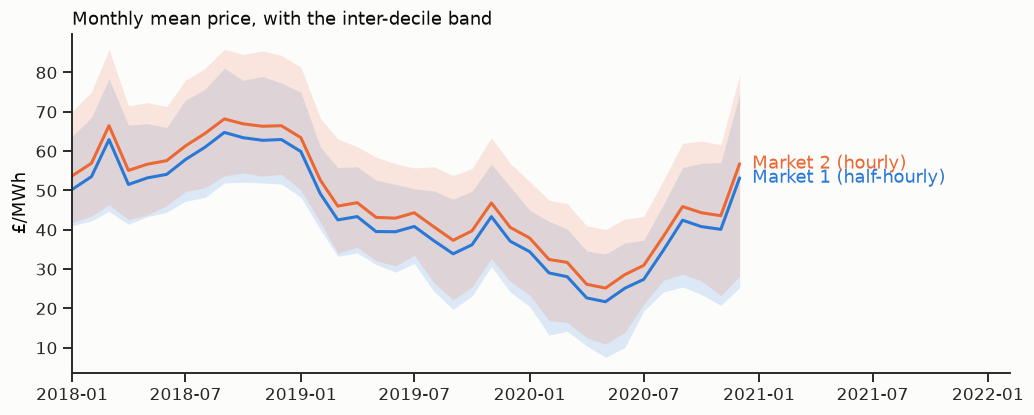

In [9]:
monthly = plan[["price_1", "price_2"]].resample("MS")

fig, ax = plt.subplots(figsize=(11, 4))
for column, colour, label in (
    ("price_1", CHARGE, "Market 1 (half-hourly)"),
    ("price_2", DISCHARGE, "Market 2 (hourly)"),
):
    mean = monthly[column].mean()
    ax.fill_between(
        mean.index,
        monthly[column].quantile(0.1),
        monthly[column].quantile(0.9),
        color=colour,
        alpha=0.15,
        lw=0,
    )
    ax.plot(mean.index, mean, color=colour, lw=2.0)
    ax.text(mean.index[-1] + pd.Timedelta("20D"), mean.iloc[-1], label, color=colour, va="center")

ax.set_ylabel("£/MWh")
ax.set_title("Monthly mean price, with the inter-decile band", loc="left", color=INK)
ax.set_xlim(plan.index[0], plan.index[-1] + pd.Timedelta("400D"))
sns.despine(ax=ax)
plt.show()

The level falls year on year. What the battery is paid for is the spread, and
the two parts of that spread — between the markets at one instant, and within
one market across the day — are worth separating.

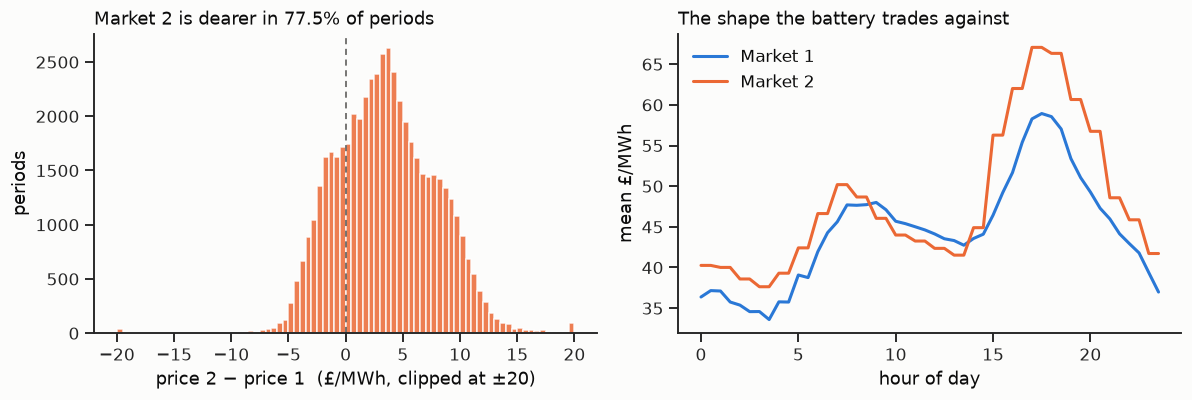

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

share_dearer = float((plan["spread"] > 0).mean())
axes[0].hist(plan["spread"].clip(-20, 20), bins=80, color=DISCHARGE, alpha=0.85)
axes[0].axvline(0.0, color=MUTED, lw=1.0, ls=(0, (4, 3)))
axes[0].set_xlabel("price 2 − price 1  (£/MWh, clipped at ±20)")
axes[0].set_ylabel("periods")
axes[0].set_title(
    f"Market 2 is dearer in {share_dearer:.1%} of periods",
    loc="left",
    color=INK,
)

half_hour = plan.index.hour + plan.index.minute / 60.0
by_half_hour = plan.groupby(half_hour)
axes[1].plot(by_half_hour["price_1"].mean(), color=CHARGE, lw=2.0, label="Market 1")
axes[1].plot(by_half_hour["price_2"].mean(), color=DISCHARGE, lw=2.0, label="Market 2")
axes[1].set_xlabel("hour of day")
axes[1].set_ylabel("mean £/MWh")
axes[1].set_title("The shape the battery trades against", loc="left", color=INK)
axes[1].legend(frameon=False)

sns.despine(fig=fig)
fig.tight_layout()
plt.show()

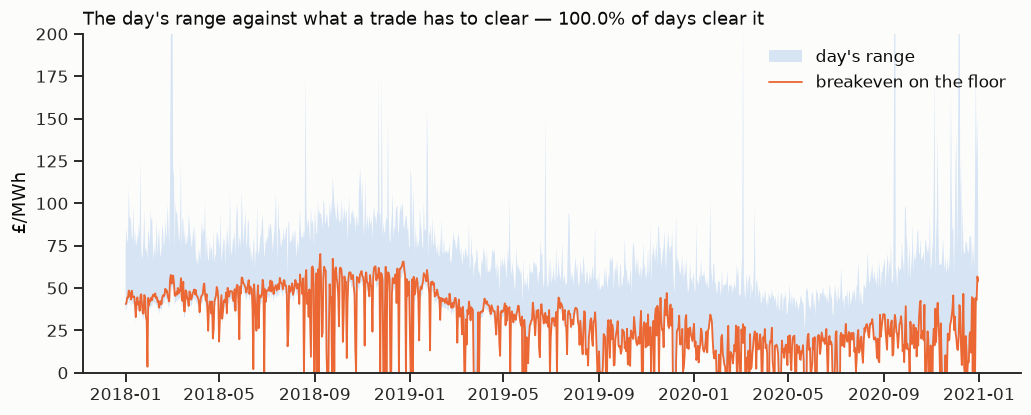

In [11]:
buy_floor = plan["buy_at"].groupby(day).min()
breakeven_level = buy_floor * (1.0 + breakeven_markup)
sell_ceiling = plan["sell_at"].groupby(day).max()
days_worth_trading = float((sell_ceiling > breakeven_level).mean())

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(
    sell_ceiling.index, buy_floor, sell_ceiling, color=CHARGE, alpha=0.18, lw=0, label="day's range"
)
ax.plot(
    breakeven_level.index, breakeven_level, color=DISCHARGE, lw=1.2, label="breakeven on the floor"
)
ax.set_ylabel("£/MWh")
ax.set_ylim(0, min(200, float(sell_ceiling.max())))
ax.set_title(
    f"The day's range against what a trade has to clear — "
    f"{days_worth_trading:.1%} of days clear it",
    loc="left",
    color=INK,
)
ax.legend(frameon=False, loc="upper right")
sns.despine(ax=ax)
plt.show()

## §3 What the plan actually does

The dispatch itself, which no document currently shows. Three zoom levels: a
couple of days traced period by period, a year as one picture, and the mean
day.

In the close-up, colour is the *market* — blue Market 1, orange Market 2, the
same as the price lines above it — and the sign is the direction: bars above
the line are energy going in, bars below it energy going out.

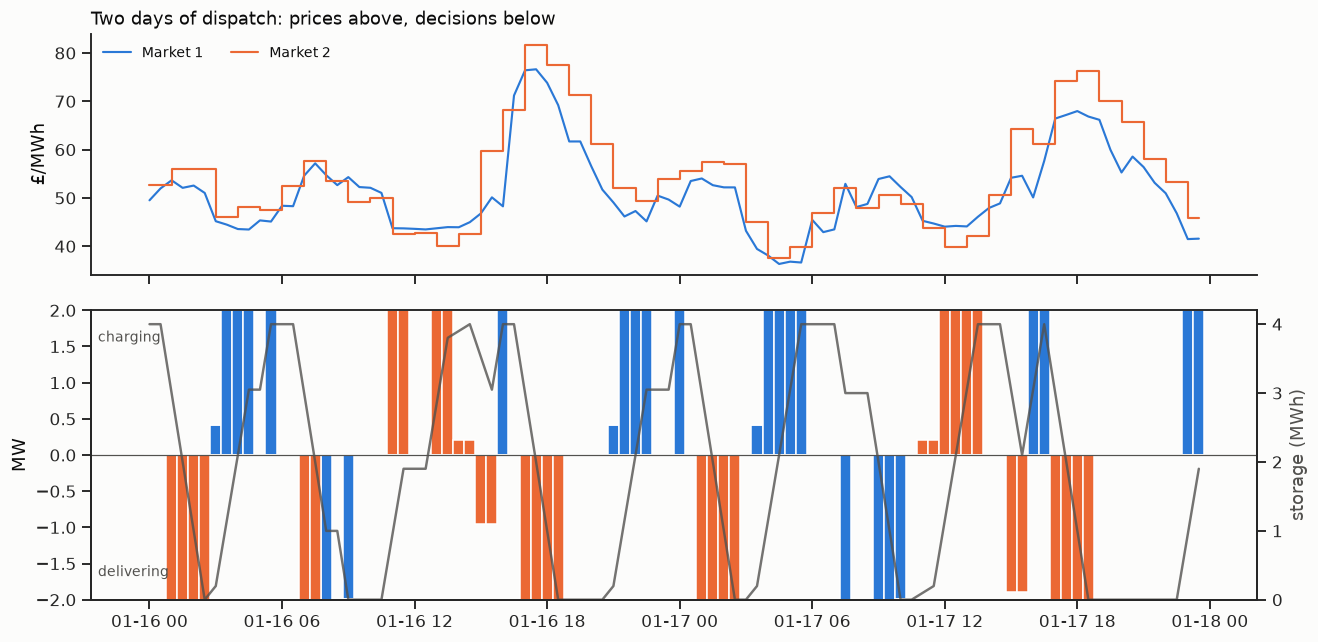

In [16]:
week = plan.loc["2018-01-16":"2018-01-17"]

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [1.0, 1.2]}
)

top.plot(week.index, week["price_1"], color=CHARGE, lw=1.4, label="Market 1")
top.plot(
    week.index, week["price_2"], color=DISCHARGE, lw=1.4, drawstyle="steps-post", label="Market 2"
)
top.set_ylabel("£/MWh")
top.legend(frameon=False, ncol=2, loc="upper left", fontsize=9)
top.set_title("Two days of dispatch: prices above, decisions below", loc="left", color=INK)

# Colour is the market, not the direction: a bar carries the same blue or
# orange as the price line it was traded against, and its sign says which way
# the energy went. Each side is stacked, so a period split across both markets
# shows as one bar in two colours.
width = pd.Timedelta("30min")
bottom.bar(week.index, week["charge_1_mw"], width=width, color=CHARGE)
bottom.bar(
    week.index, week["charge_2_mw"], width=width, bottom=week["charge_1_mw"], color=DISCHARGE
)
bottom.bar(week.index, -week["discharge_1_mw"], width=width, color=CHARGE)
bottom.bar(
    week.index,
    -week["discharge_2_mw"],
    width=width,
    bottom=-week["discharge_1_mw"],
    color=DISCHARGE,
)
bottom.axhline(0.0, color=MUTED, lw=0.8)
bottom.set_ylabel("MW")

# The direction is in the sign, so it is named on the axis rather than in a
# legend that would repeat the one above.
for height, text, align in ((0.93, "charging", "top"), (0.07, "delivering", "bottom")):
    bottom.text(
        0.006,
        height,
        text,
        transform=bottom.transAxes,
        color=MUTED,
        fontsize=9,
        va=align,
    )

storage = bottom.twinx()
storage.plot(week.index, week["storage_mwh"], color=MUTED, lw=1.6, alpha=0.8)
storage.set_ylabel("storage (MWh)", color=MUTED)
storage.set_ylim(0, params.nominal_volume_mwh * 1.05)
storage.grid(visible=False)

sns.despine(ax=top)
sns.despine(ax=bottom, right=False)
fig.tight_layout()
plt.show()

A year at once. Each column is a day, each row a half hour: blue is charging,
orange delivering. The diurnal pattern and its seasonal drift read together.

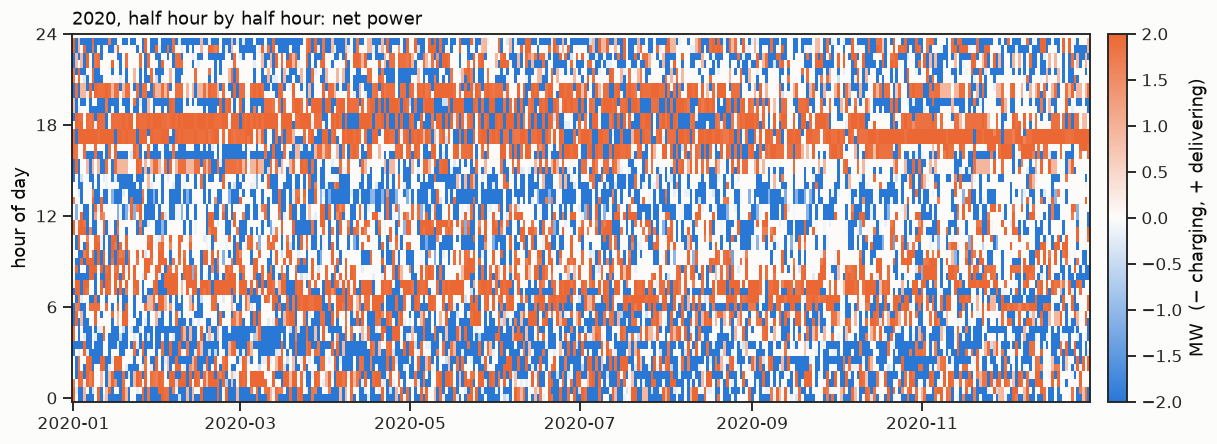

In [14]:
year = plan.loc["2020"]
grid = year["net_mw"].to_frame("net_mw")
grid["day"] = grid.index.normalize()
grid["period"] = grid.index.hour * 2 + (grid.index.minute // 30)
heat = grid.pivot_table(index="period", columns="day", values="net_mw")

fig, ax = plt.subplots(figsize=(12, 4.2))
limit = float(np.abs(heat.to_numpy()).max())
mesh = ax.pcolormesh(
    heat.columns,
    heat.index / 2.0,
    heat.to_numpy(),
    cmap=sns.blend_palette([CHARGE, SURFACE, DISCHARGE], as_cmap=True),
    vmin=-limit,
    vmax=limit,
    shading="nearest",
)
ax.set_ylabel("hour of day")
ax.set_yticks([0, 6, 12, 18, 24])
ax.set_title("2020, half hour by half hour: net power", loc="left", color=INK)
bar = fig.colorbar(mesh, ax=ax, pad=0.015)
bar.set_label("MW  (− charging, + delivering)")
fig.tight_layout()
plt.show()

### The constraints verification

§4.3 forbids charging and delivering in the same period; §4.5 holds each
Market 2 decision flat across its hour. Both are asserted in `tests/`
against freshly solved windows — here they are read off the committed plan,
which is the artefact every figure above and every number in `results.md`
comes from.

In [19]:
TOLERANCE = 1e-5
both = int(((plan["charge_mw"] > TOLERANCE) & (plan["discharge_mw"] > TOLERANCE)).sum())

hour = plan.index.floor("h")
flatness = plan.groupby(hour)[["charge_2_mw", "discharge_2_mw"]].agg(lambda s: s.max() - s.min())
not_flat = int((flatness > TOLERANCE).any(axis=1).sum())

over_rate = int(
    (
        (plan["charge_mw"] > params.max_charge_mw + TOLERANCE)
        | (plan["discharge_mw"] > params.max_discharge_mw + TOLERANCE)
    ).sum()
)
over_volume = int((plan["storage_mwh"] > plan["effective_volume_mwh"] + TOLERANCE).sum())

checks = pd.Series(
    {
        "§4.3 periods both charging and delivering": both,
        "§4.5 hours with a non-flat market 2 decision": not_flat,
        "§4.3 periods over the rate limit": over_rate,
        "§4.1 periods over the degraded volume": over_volume,
        "§4.6 cycles spent beyond the budget": int(figures["cycles_used"] > params.cycle_budget),
    }
)
print(checks.to_string())
print(f"\n{'all clear' if checks.sum() == 0 else 'VIOLATIONS — see above'}")

§4.3 periods both charging and delivering       0
§4.5 hours with a non-flat market 2 decision    0
§4.3 periods over the rate limit                0
§4.1 periods over the degraded volume           0
§4.6 cycles spent beyond the budget             0

all clear


## Market Arbitrage

`results.md` reads the profit as part arbitrage over time, part the standing
gap between the two markets. Here it is split.

Take Market 1, the half-hourly market, as the reference. Valuing every
decision at the Market 1 price of its own period gives the first part: what
the same volumes would have earned traded entirely in Market 1. The rest is
what using Market 2 added, period by period. The split is exact — the two
parts sum to the profit — but the first part is a *valuation*, not a feasible
alternative plan: a plan confined to Market 1 would not face §4.5 and would
choose different volumes.

In [25]:
at_market_1 = params.dt * float(
    (plan["price_1"] * (delivered * plan["discharge_mw"] - plan["charge_mw"])).sum()
)
from_market_2 = params.dt * float(
    (plan["spread"] * (delivered * plan["discharge_2_mw"] - plan["charge_2_mw"])).sum()
)

split = pd.Series(
    {
        "time arbitrage, valued at market 1": at_market_1,
        "the market arbitrage": from_market_2,
        "profit": at_market_1 + from_market_2,
    }
)
assert abs(split["profit"] - figures["profit_gbp"]) < 0.01, "the split must be exact"
print(split.map("£{:,.0f}".format).to_string())
print(f"\nthe market 2 gap is {from_market_2 / figures['profit_gbp']:.1%} of the profit")

time arbitrage, valued at market 1    £129,005
the market arbitrage                   £78,360
profit                                £207,365

the market 2 gap is 37.8% of the profit


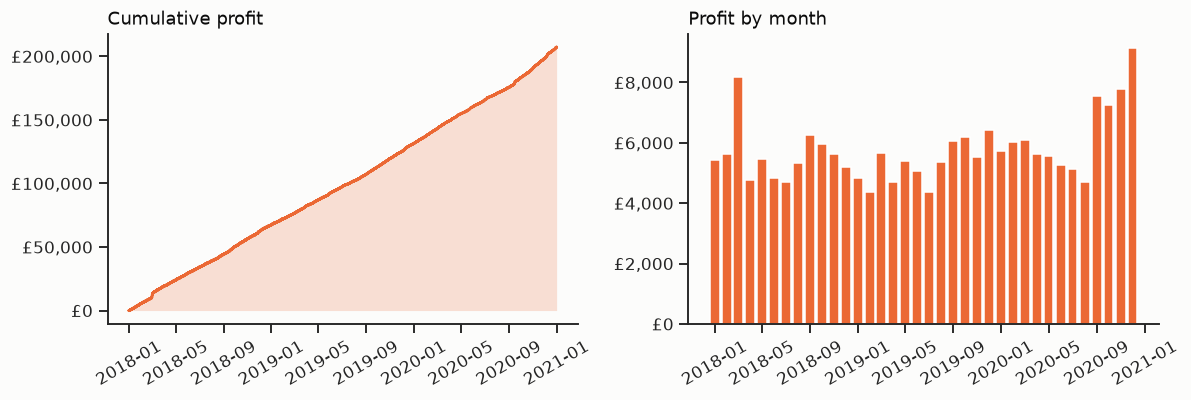

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

cumulative = plan["net_revenue_gbp"].cumsum()
axes[0].fill_between(cumulative.index, 0, cumulative, color=DISCHARGE, alpha=0.2, lw=0)
axes[0].plot(cumulative.index, cumulative, color=DISCHARGE, lw=1.8)
axes[0].yaxis.set_major_formatter(GBP)
axes[0].set_title("Cumulative profit", loc="left", color=INK)
axes[0].tick_params(axis="x", rotation=30)

monthly_profit = plan["net_revenue_gbp"].resample("MS").sum()
axes[1].bar(
    monthly_profit.index,
    monthly_profit,
    width=25,
    color=np.where(monthly_profit >= 0, DISCHARGE, CHARGE),
)
axes[1].axhline(0.0, color=MUTED, lw=0.8)
axes[1].yaxis.set_major_formatter(GBP)
axes[1].set_title("Profit by month", loc="left", color=INK)
axes[1].tick_params(axis="x", rotation=30)

sns.despine(fig=fig)
fig.tight_layout()
plt.show()

In [18]:
# Year by year, as results.md tables it, with the spread added as the column
# that explains the progression.
years = plan.groupby(plan.index.year)
cumulative_cycles = years["cycles"].last()

by_year = pd.DataFrame(
    {
        "profit_gbp": years["net_revenue_gbp"].sum(),
        "mean_price_1": years["price_1"].mean(),
        "mean_price_2": years["price_2"].mean(),
        "cycles": cumulative_cycles.diff().fillna(cumulative_cycles.iloc[0]),
        "mean_day_range": daily["day_range"].groupby(daily.index.year).mean(),
        "mean_harvestable": daily["harvestable_spread"].groupby(daily.index.year).mean(),
        "profit_per_cycle": years["net_revenue_gbp"].sum()
        / cumulative_cycles.diff().fillna(cumulative_cycles.iloc[0]),
    }
)
by_year.style.format("{:,.2f}").format({"profit_gbp": "£{:,.0f}", "cycles": "{:,.0f}"})

,profit_gbp,mean_price_1,mean_price_2,cycles,mean_day_range,mean_harvestable,profit_per_cycle
timestamp,,,,,,,
2018,"£67,478",58.217569,61.716299,967,46.817603,29.602177,69.799518
2019,"£63,991",41.839190,45.349668,"1,165",41.422288,26.576231,54.908291
2020,"£75,897",33.329380,36.838214,"1,310",48.545683,29.851409,57.914305


## Cycles and wear

3,443 of 5,000 cycles spent, so the cap of §4.6 never bound and the shadow
price of §6 stayed at zero. The pro-rated reading of §5 — three years of a
ten-year life, 1,500 cycles — is crossed less than halfway through, which is
where λ would start to matter.

In [19]:
prorated = prorated_cycle_budget(spec, len(plan))
crossing = plan.index[int(np.searchsorted(plan["cycles"].to_numpy(), prorated))]
print(f"full budget      {params.cycle_budget:,.0f} cycles — {figures['cycles_used']:,.0f} spent")
print(f"pro-rated (§5)   {prorated:,.0f} cycles — crossed on {crossing:%Y-%m-%d}")

full budget      5,000 cycles — 3,443 spent
pro-rated (§5)   1,500 cycles — crossed on 2019-06-29


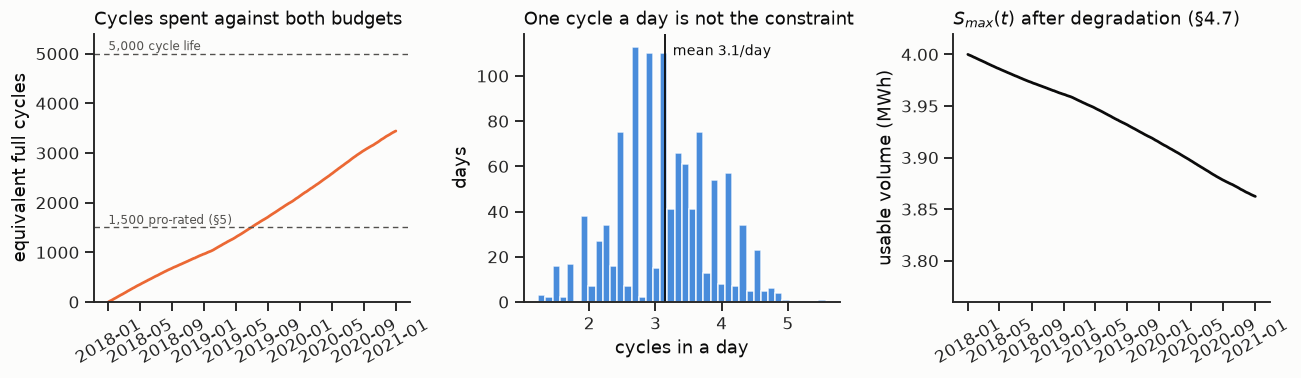

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

axes[0].plot(plan.index, plan["cycles"], color=DISCHARGE, lw=1.8)
for level, label in ((params.cycle_budget, "5,000 cycle life"), (prorated, "1,500 pro-rated (§5)")):
    axes[0].axhline(level, color=MUTED, lw=0.9, ls=(0, (4, 3)))
    axes[0].text(plan.index[0], level + 70, label, color=MUTED, fontsize=8)
axes[0].set_ylabel("equivalent full cycles")
axes[0].set_ylim(0, params.cycle_budget * 1.08)
axes[0].set_title("Cycles spent against both budgets", loc="left", color=INK)
axes[0].tick_params(axis="x", rotation=30)

axes[1].hist(daily["cycles"], bins=40, color=CHARGE, alpha=0.85)
mean_per_day = float(daily["cycles"].mean())
axes[1].axvline(mean_per_day, color=INK, lw=1.2)
axes[1].text(
    mean_per_day, axes[1].get_ylim()[1] * 0.92, f"  mean {mean_per_day:.1f}/day", fontsize=9
)
axes[1].set_xlabel("cycles in a day")
axes[1].set_ylabel("days")
axes[1].set_title("One cycle a day is not the constraint", loc="left", color=INK)

axes[2].plot(plan.index, plan["effective_volume_mwh"], color=INK, lw=1.8)
axes[2].set_ylabel("usable volume (MWh)")
axes[2].set_ylim(params.nominal_volume_mwh * 0.94, params.nominal_volume_mwh * 1.005)
axes[2].set_title("$S_{max}(t)$ after degradation (§4.7)", loc="left", color=INK)
axes[2].tick_params(axis="x", rotation=30)

sns.despine(fig=fig)
fig.tight_layout()
plt.show()

In [21]:
# What the wear cost, priced at the spreads the plan actually realised. Not a
# charge in the objective — §5 keeps degradation physical, in the volume — so
# this is the opportunity cost of the capacity given up, for context.
volume_lost_mwh = params.nominal_volume_mwh - float(figures["final_usable_volume_mwh"])
realised_margin = float(
    figures["mean_sell_price_gbp_per_mwh"] - figures["mean_buy_price_gbp_per_mwh"]
)
cycles_per_day = float(daily["cycles"].mean())
forgone_per_year = volume_lost_mwh * realised_margin * cycles_per_day * 365.25

print(f"volume lost over the horizon  {volume_lost_mwh:.3f} MWh of {params.nominal_volume_mwh:.2f}")
print(f"realised margin per MWh       £{realised_margin:,.2f}")
print(
    f"forgone trading, per year     £{forgone_per_year:,.0f} at {cycles_per_day:.1f} cycles a day"
)

volume lost over the horizon  0.138 MWh of 4.00
realised margin per MWh       £19.63
forgone trading, per year     £3,101 at 3.1 cycles a day


## Spreads

`results.md` reads 2020 — the cheapest year and the most profitable — as the
battery being paid for the spread rather than the level. That reading rests
on three annual rows. There are 1,096 daily ones.

First, *which* spread. "The day's spread" has at least four readings, and
they are not interchangeable:

- **the range**, highest price less lowest, which is one perfect trade and
  the battery makes about three a day;
- **the harvestable spread** of §0, the same thing averaged over as many
  periods as the plan actually trades;
- **volatility**, the within-day standard deviation, which is agnostic about
  how the battery would capture it;
- **the realised spread**, what the plan itself paid and received that day.



In [ ]:
def _fit(x: pd.Series, y: pd.Series) -> tuple[float, float, float]:
    """Least-squares slope, intercept and R² for ``y`` on ``x``."""
    mask = x.notna() & y.notna()
    slope, intercept = np.polyfit(x[mask], y[mask], 1)
    predicted = slope * x[mask] + intercept
    # the squared error left after the fit, against the squared error you'd have from just predicting every day's mean profit
    r2 = 1.0 - float(((y[mask] - predicted) ** 2).sum() / ((y[mask] - y[mask].mean()) ** 2).sum())
    return float(slope), float(intercept), r2

In [33]:
# What each reading of "the day's spread" explains, measured the same way.
sold_gbp = (delivered * plan["discharge_mw"] * plan["sell_at"]).groupby(day).sum()
sold_mwh = (delivered * plan["discharge_mw"] * params.dt).groupby(day).sum()
bought_gbp = (plan["charge_mw"] * plan["buy_at"]).groupby(day).sum()
bought_mwh = (plan["charge_mw"] * params.dt).groupby(day).sum()

candidates = pd.DataFrame(
    {
        "the day's range": daily["day_range"],
        "harvestable spread": daily["harvestable_spread"],
        "within-day volatility": plan["sell_at"].groupby(day).std(),
        "mean |market 2 − market 1|": plan["spread"].abs().groupby(day).mean(),
        "realised by the plan": sold_gbp / sold_mwh.replace(0.0, np.nan)
        - bought_gbp / bought_mwh.replace(0.0, np.nan),
        "the price level": daily["mean_price"],
    }
)

explained = pd.DataFrame(
    [
        dict(
            zip(("£ per unit (slope)", "R²"), _fit(candidates[name], daily["profit_gbp"])[::2], strict=True)
        )
        for name in candidates
    ],
    index=candidates.columns,
)
explained["exogenous"] = [True, True, True, True, False, True]
explained.style.format({"£ per unit": "{:,.2f}", "R²": "{:.3f}"})

,£ per unit (slope),R²,exogenous
the day's range,3.346491,0.521,True
harvestable spread,6.157147,0.573,True
within-day volatility,13.513953,0.566,True
mean |market 2 − market 1|,89.960643,0.388,True
realised by the plan,3.526230,0.480,False
the price level,1.778976,0.050,True


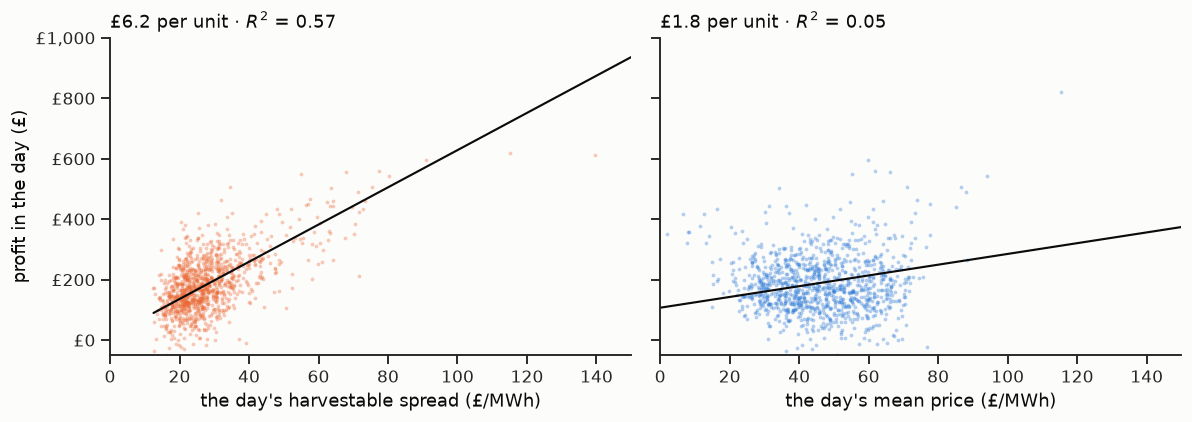

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, column, colour, label in (
    (axes[0], "harvestable_spread", DISCHARGE, "the day's harvestable spread (£/MWh)"),
    (axes[1], "mean_price", CHARGE, "the day's mean price (£/MWh)"),
):
    slope, intercept, r2 = _fit(daily[column], daily["profit_gbp"])
    ax.scatter(daily[column], daily["profit_gbp"], s=6, color=colour, alpha=0.35, lw=0)
    line = np.linspace(daily[column].min(), daily[column].max(), 50)
    ax.plot(line, slope * line + intercept, color=INK, lw=1.4)
    ax.set_xlabel(label)
    ax.set_title(f"£{slope:,.1f} per unit · $R^2$ = {r2:.2f}", loc="left", color=INK)

axes[0].set_ylabel("profit in the day (£)")
axes[0].yaxis.set_major_formatter(GBP)
for ax in axes:
    ax.set_xlim(0, 150)
    ax.set_ylim(-50, 1_000)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

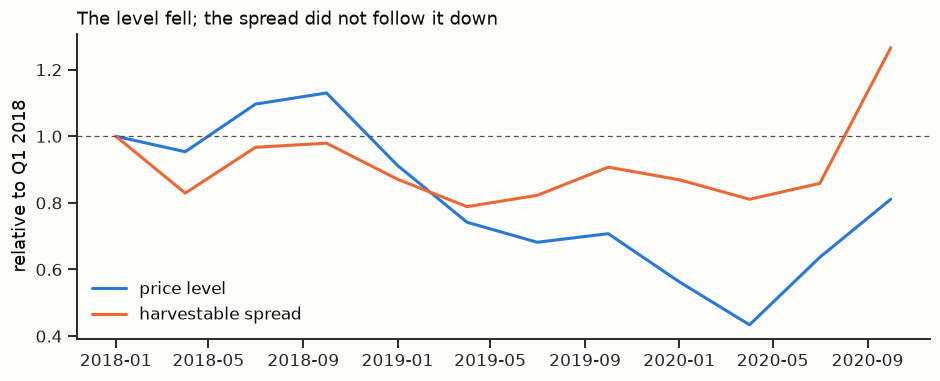

In [25]:
# The two moving apart is the mechanism the document asserts: the level fell
# while the spread widened.
quarterly = pd.DataFrame(
    {
        "mean price": daily["mean_price"].resample("QS").mean(),
        "mean harvestable spread": daily["harvestable_spread"].resample("QS").mean(),
    }
)
normalised = quarterly / quarterly.iloc[0]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(normalised.index, normalised["mean price"], color=CHARGE, lw=2.0, label="price level")
ax.plot(
    normalised.index,
    normalised["mean harvestable spread"],
    color=DISCHARGE,
    lw=2.0,
    label="harvestable spread",
)
ax.axhline(1.0, color=MUTED, lw=0.8, ls=(0, (4, 3)))
ax.set_ylabel("relative to Q1 2018")
ax.set_title("The level fell; the spread did not follow it down", loc="left", color=INK)
ax.legend(frameon=False)
sns.despine(ax=ax)
plt.show()

## Tractability

The committed measurement CSVs behind
[`tractability.md`](../docs/model/tractability.md) and
[`cycle-value-experiments.md`](../docs/model/cycle-value-experiments.md),
plotted. They are the reason the horizon is decomposed at all, and the reason
cutting planes are the default method for λ.

In [35]:
DOCS_MODEL = PLAN_PATH.parents[2] / "docs" / "model"

tractability = pd.read_csv(DOCS_MODEL / "tractability.csv")
sweep = pd.read_csv(DOCS_MODEL / "cycle-value-sweep.csv")
tolerance_sweep = pd.read_csv(DOCS_MODEL / "cycle-value-tolerance.csv")
long_horizons = pd.read_csv(DOCS_MODEL / "cycle-value-long-horizons.csv")

tractability

,window_days,periods,status,solve_seconds,objective_gbp,best_bound_gbp,gap_pct
0,1,48,Optimal,0.0,139.72,139.72,0.00
1,2,96,Optimal,0.1,331.50,331.53,0.01
2,4,192,Optimal,0.4,624.11,624.11,0.00
3,7,336,Optimal,0.9,1231.06,1231.18,0.01
4,14,672,Optimal,9.7,2370.87,2370.88,0.00
5,30,1440,Optimal,23.6,5433.95,5434.49,0.01
6,60,2880,Optimal,173.2,12955.47,12956.77,0.01
7,1096,52608,TimeLimit,3611.1,206318.80,208166.65,0.90


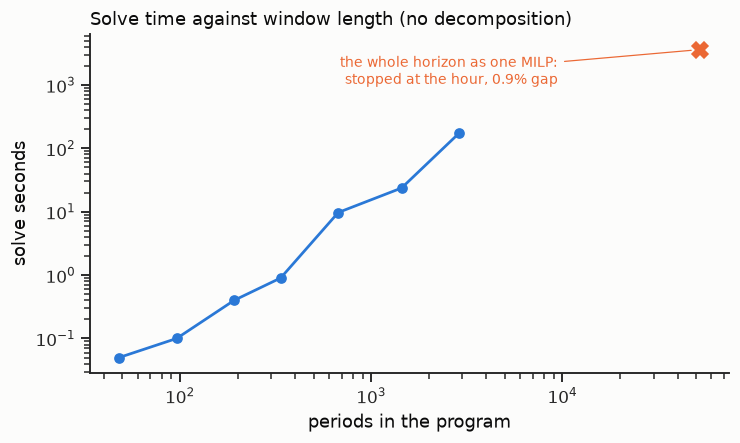

In [38]:
fig, ax = plt.subplots(figsize=(7.5, 4))

solved = tractability[tractability["status"] == "Optimal"]
stopped = tractability[tractability["status"] != "Optimal"]

ax.plot(
    solved["periods"], solved["solve_seconds"].clip(lower=0.05), "o-", color=CHARGE, lw=1.8, ms=6
)
ax.plot(stopped["periods"], stopped["solve_seconds"], "X", color=DISCHARGE, ms=11)
for _, row in stopped.iterrows():
    ax.annotate(
        f"the whole horizon as one MILP:\nstopped at the hour, {row['gap_pct']:.1f}% gap",
        xy=(row["periods"], row["solve_seconds"]),
        xytext=(row["periods"] * 0.18, row["solve_seconds"] * 0.45),
        color=DISCHARGE,
        fontsize=9,
        ha="right",
        va="center",
        arrowprops=dict(arrowstyle="-", color=DISCHARGE, lw=0.8, shrinkA=2, shrinkB=6),
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("periods in the program")
ax.set_ylabel("solve seconds")
ax.set_title(
    "Solve time against window length (no decomposition)", loc="left", color=INK
)
sns.despine(ax=ax)
plt.show()

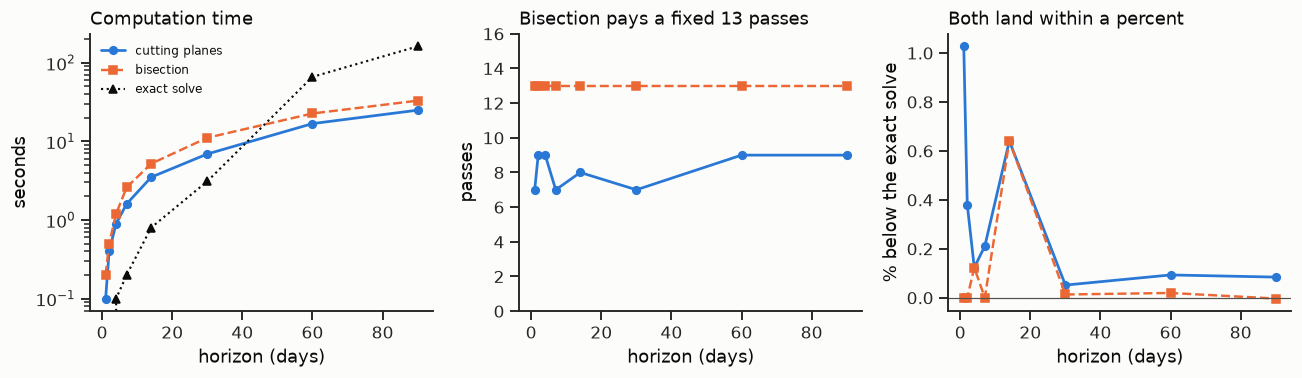

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

axes[0].plot(
    sweep["days"],
    sweep["cutting_seconds"],
    "o-",
    color=CHARGE,
    lw=1.8,
    ms=5,
    label="cutting planes",
)
axes[0].plot(
    sweep["days"],
    sweep["bisection_seconds"],
    "s--",
    color=DISCHARGE,
    lw=1.6,
    ms=5,
    label="bisection",
)
axes[0].plot(
    sweep["days"], sweep["exact_seconds"], "^:", color=INK, lw=1.4, ms=5, label="exact solve"
)
axes[0].set_yscale("log")
axes[0].set_xlabel("horizon (days)")
axes[0].set_ylabel("seconds")
axes[0].set_title("Computation time", loc="left", color=INK)
axes[0].legend(frameon=False, fontsize=8)

axes[1].plot(sweep["days"], sweep["cutting_passes"], "o-", color=CHARGE, lw=1.8, ms=5)
axes[1].plot(sweep["days"], sweep["bisection_passes"], "s--", color=DISCHARGE, lw=1.6, ms=5)
axes[1].set_xlabel("horizon (days)")
axes[1].set_ylabel("passes")
axes[1].set_ylim(0, 16)
axes[1].set_title("Bisection pays a fixed 13 passes", loc="left", color=INK)

gap_cutting = 100 * (1 - sweep["cutting_profit_gbp"] / sweep["exact_profit_gbp"])
gap_bisection = 100 * (1 - sweep["bisection_profit_gbp"] / sweep["exact_profit_gbp"])
axes[2].plot(sweep["days"], gap_cutting, "o-", color=CHARGE, lw=1.8, ms=5)
axes[2].plot(sweep["days"], gap_bisection, "s--", color=DISCHARGE, lw=1.6, ms=5)
axes[2].axhline(0.0, color=MUTED, lw=0.8)
axes[2].set_xlabel("horizon (days)")
axes[2].set_ylabel("% below the exact solve")
axes[2].set_title("Both land within a percent", loc="left", color=INK)

sns.despine(fig=fig)
fig.tight_layout()
plt.show()

Bisection costs more passes and certifies nothing — its bound columns are
empty by construction. Cutting planes return a dual bound with the plan,
which is what the gap column below is. The λ the two methods find agree to
within a pound or two, on budgets set to half what the horizon would spend.

In [32]:
comparison = sweep[
    [
        "days",
        "budget_cycles",
        "cutting_lambda",
        "bisection_lambda",
        "cutting_gap_pct",
        "profit_delta_pct",
    ]
].rename(
    columns={
        "cutting_lambda": "λ cutting",
        "bisection_lambda": "λ bisection",
        "cutting_gap_pct": "cutting gap %",
        "profit_delta_pct": "cutting vs bisection %",
    }
)
comparison.style.format("{:,.2f}").hide(axis="index")

days,budget_cycles,λ cutting,λ bisection,cutting gap %,cutting vs bisection %
1.00,1.83,11.33,11.28,0.00,-1.03
2.00,3.29,18.82,18.80,0.00,-0.38
4.00,6.24,21.52,21.48,0.00,0.00
7.00,10.76,22.66,22.51,0.01,-0.21
14.00,19.67,24.49,24.71,0.01,0.00
30.00,43.65,28.85,28.47,0.00,-0.04
60.00,87.83,29.86,30.81,0.01,-0.07
90.00,133.03,36.17,36.77,0.01,-0.09


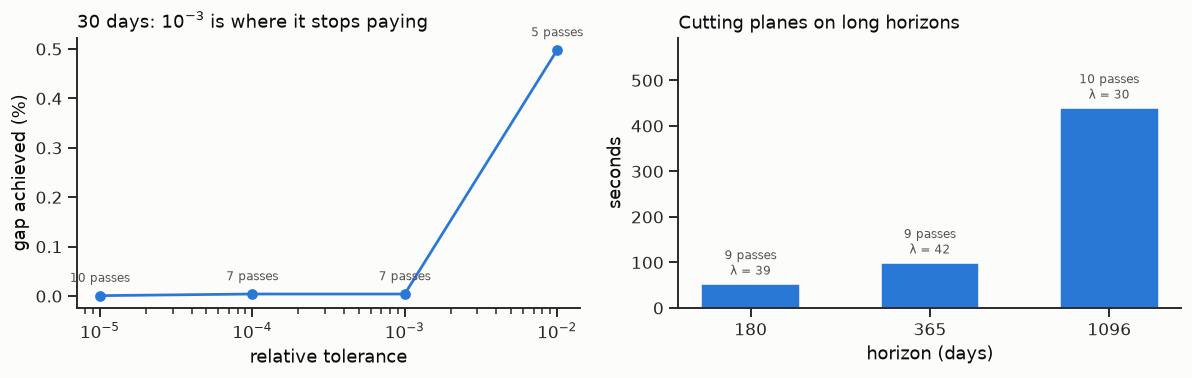

In [33]:
# Where the tolerance stops buying anything, and the method on horizons long
# enough to matter.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

axes[0].plot(
    tolerance_sweep["tolerance"], tolerance_sweep["gap_pct"], "o-", color=CHARGE, lw=1.8, ms=6
)
for _, row in tolerance_sweep.iterrows():
    axes[0].annotate(
        f"{int(row['passes'])} passes",
        xy=(row["tolerance"], row["gap_pct"]),
        xytext=(0, 9),
        textcoords="offset points",
        fontsize=8,
        color=MUTED,
        ha="center",
    )
axes[0].set_xscale("log")
axes[0].set_xlabel("relative tolerance")
axes[0].set_ylabel("gap achieved (%)")
axes[0].set_title("30 days: $10^{-3}$ is where it stops paying", loc="left", color=INK)

slots = np.arange(len(long_horizons))
axes[1].bar(slots, long_horizons["cutting_seconds"], width=0.55, color=CHARGE)
axes[1].set_xticks(slots)
axes[1].set_xticklabels(long_horizons["days"].astype(int).astype(str))
for slot, row in zip(slots, long_horizons.itertuples(), strict=True):
    axes[1].annotate(
        f"{row.cutting_passes} passes\nλ = {row.cutting_lambda:.0f}",
        xy=(slot, row.cutting_seconds),
        xytext=(0, 6),
        textcoords="offset points",
        fontsize=8,
        color=MUTED,
        ha="center",
    )
axes[1].set_xlabel("horizon (days)")
axes[1].set_ylabel("seconds")
axes[1].set_ylim(0, long_horizons["cutting_seconds"].max() * 1.35)
axes[1].set_title("Cutting planes on long horizons", loc="left", color=INK)

sns.despine(fig=fig)
fig.tight_layout()
plt.show()